# PS1 — Currencies: intraday descriptive statistics

The three EBS pairs required by the homework, over one full session
(**2012-01-25, 09:30–16:00**):

| | pair | ~rate | quoted in |
|---|---|---|---|
| major | **EUR/USD** | 1.297 → 1.311 | USD per EUR |
| major | **USD/JPY** | 78.06 → 77.74 | JPY per USD |
| cross | **EUR/JPY** | 101.26 → 101.94 | JPY per EUR |

They are not three independent instruments: EUR/JPY is the product of the other two,
which is what makes part (l) possible.

`fx.py` replays the EBS level-update feed into a limit order book and hands back the
same objects `mbo.py` produces for the equities, so `hfstats.py` computes parts
(a)–(k) for both panels from a single definition.

Four features of this feed shape everything below, and differ sharply from ITCH:

1. **Level updates, not orders.** A message says "this side, this price, now holds
   this much"; `SIZE = 0` removes the level. There are no order ids, so there is no
   add/cancel count to report — which is why the homework asks for order counts on
   ITCH only. What we can count is *messages*, and those net together an unknown
   number of dealer actions.
2. **The book is capped at ten levels a side.** Depth past the tenth level is not
   missing from the file, it is unobservable. Every depth number here is a lower
   bound in a way the ITCH numbers are not.
3. **Timestamps are stamped to 100 ms**, against nanoseconds for ITCH, and many
   updates share one. The book is snapshotted once per timestamp, after the whole
   batch carrying it has been applied — applying updates one at a time invents
   crossed books the feed never showed.
4. **The trade tape lags the book.** Matched at a print's own timestamp, only 47% of
   EUR/USD prints sit at or outside the touch and buys average just 0.33 spreads
   above sells — implausible for a market with no hidden liquidity. Backing the
   match up 200 ms gives 85% and 0.91 spreads, and 200 ms is the optimum on all
   three pairs independently. `fx.LAG` applies that offset.

In [1]:
import numpy as np
import pandas as pd

import fx
import hfstats as hs
import plots
from hfstats import FREQS, MINUTE, summary

books = fx.load()
eurusd, usdjpy, eurjpy = (books[p] for p in fx.PAIRS)

books

{'EUR/USD': <Book EUR/USD: 14,535 trades, 58,316 quote updates>,
 'USD/JPY': <Book USD/JPY: 6,041 trades, 31,436 quote updates>,
 'EUR/JPY': <Book EUR/JPY: 1,542 trades, 34,360 quote updates>}

## The three pairs

Sizes are in **millions of the base currency** (EUR for EUR/USD and EUR/JPY, USD for
USD/JPY) — EBS quotes in millions and every size in the file is a whole number of
them. `dollar volume` converts to USD millions, which for EUR/JPY needs the EUR/USD
mid prevailing at each print.

The ordering is the one FX microstructure predicts: the two majors are cheaper and
far more active than the cross, and EUR/JPY — which can always be manufactured from
the other two — is the widest of the three.

In [2]:
overview = pd.DataFrame({
    p: {
        "tick size": b.tick,
        "trades": len(b.trades),
        "volume (mm base)": b.trades["size"].sum(),
        "dollar volume (USD mm)": b.trades.value.sum(),
        "quote updates": len(b.quotes),
        "mean spread (ticks)": b.grid.spread.mean() / b.tick,
        "mean spread (bps)": (1e4 * b.grid.spread / b.grid.mid).mean(),
        "mean BBO depth (mm)": (b.grid.bid_sz + b.grid.ask_sz).mean(),
        "mean book depth (mm)": (b.grid.bid_tot + b.grid.ask_tot).mean(),
        "crossed batches": b.n_crossed,
    } for p, b in books.items()
})
overview.round(3)

,EUR/USD,USD/JPY,EUR/JPY
tick size,0.000,0.001,0.001
trades,14535.000,6041.000,1542.000
volume (mm base),23749.000,9673.000,2170.000
dollar volume (USD mm),30950.046,9673.000,2827.349
quote updates,58316.000,31436.000,34360.000
mean spread (ticks),11.139,7.895,18.701
mean spread (bps),0.855,1.013,1.842
mean BBO depth (mm),4.051,4.414,3.463
mean book depth (mm),50.556,50.119,36.723
crossed batches,153.000,65.000,3.000


### Data quality

Two things worth stating before the statistics rest on them.

**Momentary crossed books.** Applying a timestamp's updates as one batch removes
almost all crossing, but 153 EUR/USD batches (0.2%), 65 USD/JPY and 3 EUR/JPY still
leave the book locked or crossed. These are blanked out of the quote and grid frames
rather than repaired, so they show up as the small `NaN` share below.

**Trade signs.** The aggressor flag is the exchange's own label and is used as the
sign. `sign_disagrees` counts prints whose price sits on the far side of the
200 ms-prior mid from that flag — the residual disagreement after correcting for the
tape lag, and a fair measure of how much of the signing is genuinely uncertain.

In [3]:
pd.DataFrame({
    p: {
        "grid seconds": len(b.grid),
        "grid NaN (%)": 100 * b.grid.mid.isna().mean(),
        "trades with no prior quote": int(b.trades.mid.isna().sum()),
        "sign disagrees with quote (%)": 100 * b.trades.sign_disagrees.mean(),
        "buys at/above prior ask (%)": 100 * b.trades.eval("sign == 1 and price >= ask").sum()
                                       / max((b.trades["sign"] == 1).sum(), 1),
        "sells at/below prior bid (%)": 100 * b.trades.eval("sign == -1 and price <= bid").sum()
                                        / max((b.trades["sign"] == -1).sum(), 1),
    } for p, b in books.items()
}).round(2)

,EUR/USD,USD/JPY,EUR/JPY
grid seconds,23400.00,23400.00,23400.00
grid NaN (%),0.23,0.10,0.00
trades with no prior quote,0.00,0.00,0.00
sign disagrees with quote (%),16.71,19.38,15.43
buys at/above prior ask (%),75.81,71.58,81.91
sells at/below prior bid (%),75.44,74.60,75.24


## Part (a) — dollar trading volume per minute

Traded notional in USD millions, summed within each minute.

In [4]:
a = {p: hs.dollar_volume_per_minute(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in a.items()}, names=["pair", "series"]).round(2)

,,count,mean,std,min,25%,50%,75%,max
pair,series,,,,,,,,
EUR/USD,dollar_volume,390.0,79.36,98.79,0.0,28.8,51.01,88.60,1166.95
USD/JPY,dollar_volume,390.0,24.80,31.94,0.0,7.0,16.00,29.00,267.00
EUR/JPY,dollar_volume,389.0,7.27,10.27,0.0,1.3,3.89,9.12,70.00


## Part (b) — number of trades and messages per minute

Trades are prints on the deal feed. `updates` and `deletes` are book messages —
**not** order counts, for the reason given at the top; the homework restricts order
counts to ITCH precisely because EBS cannot supply them. The delete share is still
informative as the EBS analogue of a cancel-to-add ratio.

In [5]:
b_ = {p: hs.counts_per_minute(bk) for p, bk in books.items()}
pd.concat({p: summary(v) for p, v in b_.items()}, names=["pair", "series"]).round(2)

count    mean     std   min     25%    50%     75%     max
pair    series                                                             
EUR/USD trades   390.0   37.27   36.64   0.0   16.00   27.0   42.00   340.0
        updates  390.0  627.75  388.47  77.0  366.75  555.0  766.75  2893.0
        deletes  390.0  290.74  200.26  44.0  164.00  245.0  351.75  1418.0
USD/JPY trades   390.0   15.49   16.85   0.0    5.00   11.0   20.00   155.0
        updates  390.0  326.11  233.93  16.0  168.25  267.0  429.75  1467.0
        deletes  390.0  133.59  106.34   4.0   63.25  106.5  171.00   877.0
EUR/JPY trades   390.0    3.95    4.95   0.0    1.00    2.0    5.00    37.0
        updates  390.0  299.29  177.32  32.0  181.25  264.0  375.75  1150.0
        deletes  390.0  160.82  114.59  15.0   90.25  136.0  188.75   792.0

In [6]:
pd.DataFrame({p: {
    "messages per trade": (v.updates.sum() + v.deletes.sum()) / max(v.trades.sum(), 1),
    "delete share of messages": v.deletes.sum() / (v.updates.sum() + v.deletes.sum()),
} for p, v in b_.items()}).round(2)

,EUR/USD,USD/JPY,EUR/JPY
messages per trade,24.64,29.68,116.37
delete share of messages,0.32,0.29,0.35


## Part (c) — open, close, high and low prices

Both readings: the session's OHLC, and the per-minute trade-price OHLC. Minutes with
no print stay `NaN` rather than being forward-filled, so the `count` column shows how
often each pair actually trades — EUR/JPY prints in only a small minority of minutes.

In [7]:
pd.DataFrame({p: hs.ohlc_daily(b) for p, b in books.items()})

,EUR/USD,USD/JPY,EUR/JPY
open,1.29736,78.053,101.243
high,1.31209,78.288,101.949
low,1.29470,77.560,101.200
close,1.31130,77.730,101.920


In [8]:
c = {p: hs.ohlc_per_minute(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in c.items()}, names=["pair", "series"]).round(5)

count       mean      std        min        25%        50%  \
pair    series                                                               
EUR/USD open    389.0    1.30271  0.00559    1.29488    1.29739    1.30329   
        high    389.0    1.30294  0.00563    1.29529    1.29750    1.30366   
        low     389.0    1.30253  0.00557    1.29470    1.29720    1.30292   
        close   389.0    1.30274  0.00560    1.29490    1.29740    1.30340   
USD/JPY open    377.0   77.94847  0.22262   77.57000   77.73000   77.89600   
        high    377.0   77.95709  0.22024   77.59900   77.74900   77.90700   
        low     377.0   77.93885  0.22536   77.56000   77.72800   77.87100   
        close   377.0   77.94706  0.22300   77.57000   77.73000   77.89200   
EUR/JPY open    307.0  101.53377  0.18251  101.20000  101.40000  101.49600   
        high    307.0  101.54235  0.18283  101.20300  101.40050  101.50000   
        low     307.0  101.52667  0.18345  101.20000  101.39000  101.49300   
        close   307.0  101.53479  0.18307  101.20300  101.39850  101.50000   

                      75%        max  
pair    series                        
EUR/USD open      1.30810    1.31209  
        high      1.30840    1.31209  
        low       1.30792    1.31180  
        close     1.30812    1.31209  
USD/JPY open     78.17300   78.28200  
        high     78.18000   78.28800  
        low      78.17000   78.27600  
        close    78.17400   78.28700  
EUR/JPY open    101.67550  101.94000  
        high    101.69000  101.94900  
        low     101.67200  101.94000  
        close   101.68000  101.94000

## Part (d) — VWAP per minute

Size-weighted average trade price within the minute.

In [9]:
d = {p: hs.vwap_per_minute(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in d.items()}, names=["pair", "series"]).round(5)

,,count,mean,std,min,25%,50%,75%,max
pair,series,,,,,,,,
EUR/USD,vwap,389.0,1.30274,0.00560,1.29499,1.29733,1.30326,1.30815,1.31195
USD/JPY,vwap,377.0,77.94781,0.22276,77.58266,77.73325,77.88700,78.17240,78.28039
EUR/JPY,vwap,307.0,101.53500,0.18278,101.20015,101.40050,101.50000,101.67926,101.94000


## Part (e) — BBO spread and depth per minute

Averaged over end-of-second snapshots, so every second carries equal weight.
`book_depth` is the whole ten-level book, which the fixed-depth EBS feed gives us and
ITCH would require summing an unbounded number of levels to match.

In [10]:
e = {p: hs.spread_depth_per_minute(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in e.items()}, names=["pair", "series"]).round(4)

count     mean      std      min      25%      50%  \
pair    series                                                           
EUR/USD spread      390.0   0.0001   0.0000   0.0001   0.0001   0.0001   
        spread_bps  390.0   0.8548   0.1266   0.5075   0.7743   0.8459   
        bid_sz      390.0   2.0625   1.0161   1.0167   1.5356   1.8319   
        ask_sz      390.0   1.9882   0.8611   1.0333   1.5168   1.8167   
        depth       390.0   4.0507   1.3811   2.3333   3.2500   3.7750   
        book_depth  390.0  50.5519  18.7705  29.6000  42.2033  47.1750   
USD/JPY spread      390.0   0.0079   0.0016   0.0037   0.0068   0.0078   
        spread_bps  390.0   1.0130   0.2047   0.4824   0.8669   0.9978   
        bid_sz      390.0   2.1104   1.0068   1.0000   1.4833   1.8500   
        ask_sz      390.0   2.3035   1.9512   1.0000   1.4833   1.8500   
        depth       390.0   4.4139   2.2777   2.1000   3.2008   3.8417   
        book_depth  390.0  50.1255  14.8217  30.5167  40.3042  47.8583   
EUR/JPY spread      390.0   0.0187   0.0033   0.0071   0.0167   0.0189   
        spread_bps  390.0   1.8415   0.3218   0.6966   1.6481   1.8595   
        bid_sz      390.0   1.4665   0.5513   1.0000   1.1333   1.3167   
        ask_sz      390.0   1.9965   3.8187   1.0000   1.1667   1.3833   
        depth       390.0   3.4629   3.8552   2.0000   2.5000   2.8404   
        book_depth  390.0  36.7229   9.7114  25.2000  30.2958  35.5750   

                        75%       max  
pair    series                         
EUR/USD spread       0.0001    0.0002  
        spread_bps   0.9303    1.2672  
        bid_sz       2.2250    9.8667  
        ask_sz       2.1833   11.0500  
        depth        4.3667   13.2333  
        book_depth  54.0292  276.5833  
USD/JPY spread       0.0088    0.0141  
        spread_bps   1.1275    1.8017  
        bid_sz       2.3667    7.5667  
        ask_sz       2.4167   21.2333  
        depth        4.9292   23.2333  
        book_depth  55.6583  148.6667  
EUR/JPY spread       0.0205    0.0335  
        spread_bps   2.0119    3.3003  
        bid_sz       1.6000    6.8000  
        ask_sz       1.7333   51.2167  
        depth        3.3500   52.6833  
        book_depth  40.2167  105.6333

## Part (f) — depth within twice the day's average spread

Size resting within one average spread either side of the mid, i.e. inside a band of
**twice** the day's mean quoted spread. The best bid sits half the prevailing spread
from the mid, so the band is empty exactly when the spread exceeds twice its average
— `frac_empty` reports how often that happens.

In [11]:
f = {p: hs.band_depth_per_minute(b) for p, b in books.items()}
for p, v in f.items():
    print(f"{p}: band = {v.attrs['band']:.5f} "
          f"({v.attrs['band'] / books[p].tick:.1f} ticks) wide")
pd.concat({p: summary(v) for p, v in f.items()}, names=["pair", "series"]).round(4)

EUR/USD: band = 0.00022 (22.3 ticks) wide
USD/JPY: band = 0.01579 (15.8 ticks) wide
EUR/JPY: band = 0.03740 (37.4 ticks) wide


count     mean     std     min      25%      50%      75%  \
pair    series                                                                  
EUR/USD band_depth  390.0  15.6219  6.1887  5.9333  11.5884  15.0750  18.5833   
        frac_empty  390.0   0.0048  0.0167  0.0000   0.0000   0.0000   0.0000   
USD/JPY band_depth  390.0  13.7632  6.7966  2.7000   8.6417  12.6167  17.2458   
        frac_empty  390.0   0.0085  0.0309  0.0000   0.0000   0.0000   0.0000   
EUR/JPY band_depth  390.0  14.0667  9.1986  5.5667   9.6792  12.5417  15.6208   
        frac_empty  390.0   0.0013  0.0128  0.0000   0.0000   0.0000   0.0000   

                        max  
pair    series               
EUR/USD band_depth  56.1833  
        frac_empty   0.1333  
USD/JPY band_depth  49.6500  
        frac_empty   0.3333  
EUR/JPY band_depth  91.2000  
        frac_empty   0.1833

## Part (g) — 5-second price impact per minute

Within each minute, regress the 5-second midquote return following each print on the
sign of that print:

$$10^4 \cdot \log\!\big(m_{t+5s}/m_t\big) \;=\; \alpha + \lambda \, s_t + \varepsilon_t,
\qquad s_t \in \{-1, +1\}$$

$\lambda$ is the midquote move a buy pushes through, in basis points. Minutes with
fewer than ten prints, or with trades on only one side, cannot identify it and are
dropped — which for EUR/JPY removes almost the whole session, so its impact estimate
rests on very few minutes and should be read with that in mind.

In [12]:
g = {p: hs.price_impact_per_minute(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in g.items()}, names=["pair", "series"]).round(4)

count     mean      std     min      25%      50%  \
pair    series                                                          
EUR/USD lambda_bps  352.0   0.2215   0.1652 -0.3328   0.1145   0.2000   
        alpha_bps   352.0   0.0116   0.3778 -1.0138  -0.1622  -0.0046   
        n_trades    390.0  37.2641  36.6398  0.0000  16.0000  27.0000   
USD/JPY lambda_bps  209.0   0.2229   0.1935 -0.3064   0.0825   0.2129   
        alpha_bps   209.0  -0.0247   0.4580 -1.9202  -0.2801  -0.0025   
        n_trades    390.0  15.4897  16.8535  0.0000   5.0000  11.0000   
EUR/JPY lambda_bps   41.0   0.5253   0.4595 -0.0211   0.1592   0.4251   
        alpha_bps    41.0  -0.1016   0.6912 -1.4557  -0.4172  -0.1557   
        n_trades    389.0   3.9640   4.9486  0.0000   1.0000   2.0000   

                        75%       max  
pair    series                         
EUR/USD lambda_bps   0.3021    1.0985  
        alpha_bps    0.1790    3.6902  
        n_trades    42.0000  340.0000  
USD/JPY lambda_bps   0.3287    0.9196  
        alpha_bps    0.2557    1.1313  
        n_trades    20.0000  155.0000  
EUR/JPY lambda_bps   0.8055    1.7649  
        alpha_bps    0.2444    1.6119  
        n_trades     5.0000   37.0000

## Part (h) — one-second and one-minute midquote and transaction price series

The last quote and the last print in each interval. Intervals with no trade inherit
the previous price, so the two series stay on a common clock.

In [13]:
h = {p: {fq: hs.price_series(b, fq) for fq in FREQS} for p, b in books.items()}
pd.concat({(p, fq): summary(v) for p, d_ in h.items() for fq, v in d_.items()},
          names=["pair", "freq", "series"]).round(5)

count       mean      std        min        25%  \
pair    freq series                                                      
EUR/USD 1s   mid     23394.0    1.30272  0.00558    1.29472    1.29734   
             trade   23394.0    1.30272  0.00559    1.29479    1.29734   
        1min mid       390.0    1.30273  0.00560    1.29493    1.29739   
             trade     390.0    1.30272  0.00560    1.29490    1.29740   
USD/JPY 1s   mid     23392.0   77.95035  0.22130   77.56400   77.74100   
             trade   23392.0   77.95012  0.22120   77.56000   77.74000   
        1min mid       390.0   77.94971  0.22191   77.56550   77.74000   
             trade     390.0   77.94934  0.22184   77.57000   77.74000   
EUR/JPY 1s   mid     23341.0  101.54691  0.18404  101.19800  101.40350   
             trade   23341.0  101.54586  0.18477  101.20000  101.40000   
        1min mid       390.0  101.54604  0.18492  101.20450  101.40125   
             trade     390.0  101.54564  0.18520  101.20300  101.40000   

                           50%        75%        max  
pair    freq series                                   
EUR/USD 1s   mid       1.30329    1.30816    1.31206  
             trade     1.30330    1.30817    1.31209  
        1min mid       1.30335    1.30814    1.31206  
             trade     1.30335    1.30812    1.31209  
USD/JPY 1s   mid      77.89500   78.17400   78.28450  
             trade    77.89500   78.17100   78.28800  
        1min mid      77.89550   78.17388   78.28350  
             trade    77.89750   78.17175   78.28700  
EUR/JPY 1s   mid     101.50200  101.68800  101.95250  
             trade   101.50100  101.69000  101.94400  
        1min mid     101.49925  101.68600  101.93800  
             trade   101.50000  101.69000  101.94000

## Part (i) — log returns

$r_t = \log(p_t) - \log(p_{t-1})$, in basis points, for both series.

In [14]:
i = {p: {fq: hs.log_returns(v) for fq, v in d_.items()} for p, d_ in h.items()}
pd.concat({(p, fq): summary(1e4 * v) for p, d_ in i.items() for fq, v in d_.items()},
          names=["pair", "freq", "series"]).round(4)

count    mean     std      min     25%     50%     75%  \
pair    freq series                                                             
EUR/USD 1s   mid     23393.0  0.0045  0.3147  -3.4380 -0.0383  0.0000  0.0385   
             trade   23393.0  0.0046  0.3537  -3.8205  0.0000  0.0000  0.0000   
        1min mid       389.0  0.2799  2.6994 -10.3694 -1.0807  0.0771  1.4943   
             trade     389.0  0.2799  2.7478 -10.7140 -1.0713  0.0000  1.5313   
USD/JPY 1s   mid     23391.0 -0.0017  0.2537  -4.9958  0.0000  0.0000  0.0000   
             trade   23391.0 -0.0018  0.3001  -4.4835  0.0000  0.0000  0.0000   
        1min mid       389.0 -0.1063  2.7128 -24.6751 -1.0909  0.0000  1.0290   
             trade     389.0 -0.1076  2.7394 -21.5341 -1.2790  0.0000  1.2789   
EUR/JPY 1s   mid     23340.0  0.0029  0.3077  -6.1600  0.0000  0.0000  0.0000   
             trade   23340.0  0.0029  0.3171  -6.9059  0.0000  0.0000  0.0000   
        1min mid       389.0  0.1743  2.4374 -12.5218 -0.9855  0.0493  1.3757   
             trade     389.0  0.1713  2.4813 -10.3530 -0.9831  0.0000  1.3821   

                         max  
pair    freq series           
EUR/USD 1s   mid      4.4632  
             trade    4.1257  
        1min mid     15.5533  
             trade   15.1325  
USD/JPY 1s   mid      4.1088  
             trade    6.4214  
        1min mid      9.2615  
             trade    9.9050  
EUR/JPY 1s   mid      3.2948  
             trade    7.1952  
        1min mid     11.9798  
             trade   12.0246

## Part (j) — realized variance

$RV = \sum_t r_t^2$ over the session. Two separate microstructure effects show up
here and they push in **opposite** directions, so it is worth separating them.

* **Across series, at a fixed frequency:** transaction RV exceeds midquote RV
  (EUR/USD at 1s: 2927 vs 2320 bps²). That is bid–ask bounce — consecutive prints
  straddle the spread, adding variance the mid never sees.
* **Across frequencies, for the midquote:** RV *rises* as sampling coarsens rather
  than falling. That is the reverse of the usual equity signature, and the cause is
  in the next cell: at one second the mid simply has not moved yet.

In [15]:
pd.concat({(p, fq): hs.realized_variance(v) for p, d_ in i.items() for fq, v in d_.items()},
          names=["pair", "freq", "series"])

n  realized_var  realized_vol  annualized_vol
pair    freq series                                                   
EUR/USD 1s   mid     23393      0.000023      0.004814        0.076423
             trade   23393      0.000029      0.005410        0.085881
        1min mid       389      0.000029      0.005346        0.084863
             trade     389      0.000030      0.005441        0.086368
USD/JPY 1s   mid     23391      0.000015      0.003881        0.061601
             trade   23391      0.000021      0.004589        0.072851
        1min mid       389      0.000029      0.005348        0.084893
             trade     389      0.000029      0.005400        0.085724
EUR/JPY 1s   mid     23340      0.000022      0.004701        0.074628
             trade   23340      0.000023      0.004845        0.076907
        1min mid       389      0.000023      0.004813        0.076410
             trade     389      0.000024      0.004899        0.077774

### Volatility signature

RV of the midquote against the interval it is sampled at. For a price contaminated
by bid–ask bounce this curve falls as the interval lengthens; here it *rises* for
both majors, roughly doubling for USD/JPY between one second and five minutes.

The reason is in the last column: at one-second sampling **43% of EUR/USD seconds and
64% of USD/JPY seconds carry a midquote return of exactly zero**. With a spread of
about one pip and a tick a tenth that size, the EBS mid is a coarse, sticky object —
over one second it usually has not moved at all. Those zeros drag the high-frequency
RV *below* the true variance, and the shortfall unwinds as sampling coarsens and each
interval contains at least one real quote revision.

So at one second these pairs are dominated by price discreteness and stale quotes,
not by the bounce that dominates a comparable equity series. The bounce is still
present — it is what separates the transaction column from the midquote column at any
given frequency — but it is the smaller of the two effects on the mid.

In [16]:
_freqs = ["1s", "2s", "5s", "10s", "30s", MINUTE, "2min", "5min"]


def _signature(series):
    """RV in bps^2, and the share of intervals with no price change, by frequency."""
    out = {}
    for fq in _freqs:
        r = np.log(series.resample(fq).last().ffill().dropna()).diff().dropna()
        out[fq] = {"RV (bps^2)": 1e8 * (r ** 2).sum(), "zero returns (%)": 100 * (r == 0).mean()}
    return pd.DataFrame(out).T


pd.concat({p: _signature(b.grid.mid) for p, b in books.items()},
          axis=1, names=["pair", ""]).round(1)

pair    EUR/USD                     USD/JPY                     EUR/JPY  \
     RV (bps^2) zero returns (%) RV (bps^2) zero returns (%) RV (bps^2)   
1s       2320.0             43.1     1506.1             63.5     2215.0   
2s       2355.7             27.1     1581.8             48.4     2330.0   
5s       2687.1             11.6     1688.8             28.2     2456.8   
10s      2755.2              5.1     1878.4             15.9     2421.9   
30s      2530.2              1.9     2311.9              7.4     2144.2   
1min     2857.8              1.5     2859.9              4.6     2316.9   
2min     3173.1              1.5     2695.6              1.0     1657.1   
5min     3274.4              0.0     3487.9              1.3     1655.1   

pair                   
     zero returns (%)  
1s               56.1  
2s               39.7  
5s               19.8  
10s               9.4  
30s               3.1  
1min              2.3  
2min              0.5  
5min              0.0

## Part (k) — autocorrelation of returns

Box–Pierce $Q$ tests whether the first $k$ autocorrelations are jointly zero; the ACF
and PACF show where any dependence sits. The thing to look for is bid–ask bounce: a
negative lag-1 autocorrelation in transaction returns that is absent, or much weaker,
in midquote returns, and that fades as the sampling interval lengthens past the point
where consecutive observations straddle the spread.

In [17]:
pd.concat({(p, fq): hs.autocorrelation(v) for p, d_ in i.items() for fq, v in d_.items()},
          names=["pair", "freq", "lag"]).round(4)

mid                               trade                   \
                     acf    pacf   bp_stat bp_pvalue     acf    pacf  bp_stat   
pair    freq lag                                                                
EUR/USD 1s   1    0.0227  0.0227   12.0957    0.0005 -0.0210 -0.0210  10.3642   
             2    0.0564  0.0559   86.3777    0.0000  0.0167  0.0162  16.8515   
             3    0.0459  0.0436  135.7693    0.0000  0.0283  0.0290  35.6355   
             4    0.0300  0.0252  156.8766    0.0000  0.0306  0.0316  57.5769   
             5   -0.0105 -0.0166  159.4742    0.0000 -0.0162 -0.0159  63.7390   
             6    0.0091  0.0046  161.4211    0.0000  0.0178  0.0153  71.1793   
             7   -0.0147 -0.0161  166.5075    0.0000 -0.0066 -0.0071  72.1847   
             8   -0.0084 -0.0081  168.1452    0.0000 -0.0275 -0.0284  89.8199   
             9    0.0038  0.0060  168.4917    0.0000 -0.0109 -0.0119  92.6006   
             10  -0.0229 -0.0215  180.7953    0.0000 -0.0144 -0.0149  97.4719   
        1min 1    0.0053  0.0053    0.0108    0.9172 -0.0052 -0.0052   0.0106   
             2    0.0094  0.0094    0.0451    0.9777 -0.0119 -0.0120   0.0655   
             3    0.0588  0.0592    1.3920    0.7074  0.0688  0.0693   1.9086   
             4    0.0066  0.0060    1.4092    0.8426 -0.0032 -0.0027   1.9125   
             5    0.0987  0.0992    5.1977    0.3922  0.0986  0.1020   5.6958   
             6   -0.0029 -0.0075    5.2011    0.5183  0.0086  0.0048   5.7246   
             7   -0.0712 -0.0755    7.1752    0.4109 -0.0808 -0.0800   8.2674   
             8    0.0798  0.0717    9.6496    0.2905  0.0975  0.0869  11.9687   
             9    0.0110  0.0110    9.6966    0.3756  0.0011 -0.0015  11.9692   
             10  -0.0653 -0.0718   11.3576    0.3303 -0.0586 -0.0586  13.3040   
USD/JPY 1s   1    0.0244  0.0244   13.9076    0.0002 -0.0132 -0.0132   4.0939   
             2    0.0578  0.0573   92.0871    0.0000  0.0045  0.0043   4.5668   
             3    0.0255  0.0229  107.3301    0.0000  0.0042  0.0044   4.9886   
             4    0.0421  0.0379  148.7819    0.0000  0.0353  0.0354  34.0830   
             5    0.0198  0.0155  157.9891    0.0000  0.0145  0.0154  38.9850   
             6    0.0312  0.0256  180.7388    0.0000  0.0176  0.0177  46.2150   
             7    0.0194  0.0146  189.5681    0.0000 -0.0119 -0.0119  49.5373   
             8    0.0461  0.0402  239.1886    0.0000  0.0427  0.0409  92.1128   
             9    0.0147  0.0087  244.2581    0.0000  0.0117  0.0118  95.3141   
             10  -0.0002 -0.0084  244.2587    0.0000 -0.0040 -0.0053  95.6794   
        1min 1   -0.0003 -0.0003    0.0000    0.9948 -0.0034 -0.0034   0.0044   
             2   -0.0915 -0.0920    3.2554    0.1964 -0.0995 -0.1000   3.8564   
             3    0.1355  0.1377   10.4008    0.0154  0.1277  0.1293  10.1976   
             4   -0.0114 -0.0222   10.4515    0.0335 -0.0199 -0.0317  10.3516   
             5   -0.0127  0.0132   10.5143    0.0619 -0.0067  0.0201  10.3689   
             6    0.0805  0.0615   13.0353    0.0425  0.0663  0.0465  12.0774   
             7   -0.0982 -0.1007   16.7833    0.0188 -0.0941 -0.0921  15.5245   
             8    0.0001  0.0175   16.7833    0.0324  0.0459  0.0615  16.3446   
             9    0.0672  0.0320   18.5387    0.0294  0.0615  0.0287  17.8172   
             10   0.0401  0.0713   19.1645    0.0382  0.0067  0.0436  17.8348   
EUR/JPY 1s   1    0.0373  0.0373   32.4339    0.0000  0.0147  0.0147   5.0126   
             2    0.0276  0.0263   50.2436    0.0000  0.0014  0.0012   5.0614   
             3    0.0089  0.0069   52.0933    0.0000  0.0098  0.0098   7.3196   
             4    0.0109  0.0096   54.8714    0.0000  0.0254  0.0251  22.3658   
             5   -0.0101 -0.0113   57.2683    0.0000 -0.0023 -0.0031  22.4940   
             6   -0.0093 -0.0091   59.2734    0.0000 -0.0177 -0.0178  29.7662   
             7   -0.0163 -0.0153   65.4811    0.0000

## Part (l) — triangular arbitrage

EUR/JPY can be traded directly or manufactured through the dollar, so the two prices
must agree. Buying a synthetic euro means paying the EUR/USD ask and then the
USD/JPY ask; selling one means taking both bids:

$$\text{synthetic ask} = a_{\text{EUR/USD}} \cdot a_{\text{USD/JPY}}, \qquad
  \text{synthetic bid} = b_{\text{EUR/USD}} \cdot b_{\text{USD/JPY}}$$

which leaves two ways to be paid, each needing all three legs at once:

* **direct cheap** — buy EUR/JPY at its ask, sell the synthetic: $\text{synth bid} - a_{\text{EUR/JPY}}$
* **direct rich** — sell EUR/JPY at its bid, buy the synthetic: $b_{\text{EUR/JPY}} - \text{synth ask}$

Quantity is set by the thinnest leg, with every leg converted to millions of euro —
so it is the size of the round trip that can be put on, not the size of any one
quote. All three feeds are sampled on the common one-second clock the homework asks
for.

In [18]:
tri = fx.triangular(books)
fx.triangular_summary(tri).round(4)

seconds observed               23322.0000
seconds with an opportunity       91.0000
frequency (% of seconds)           0.3902
episodes                          63.0000
mean duration (s)                  1.4444
median duration (s)                1.0000
max duration (s)                   7.0000
mean edge (bps)                    0.2887
max edge (bps)                     1.7764
mean quantity (mm EUR)             1.0436
median quantity (mm EUR)           0.7715
total profit (USD mm)              0.0031
cheap-side seconds                59.0000
rich-side seconds                 32.0000
dtype: float64

### Are these real, or artefacts?

Two ways the headline number could be spurious, both checked rather than assumed.

**Stale quotes.** Sampling three independently-updating feeds on a common clock can
line up quotes that were never simultaneously live. If that drove the result, the
opportunity seconds would sit behind *older* quotes than average. They sit behind
newer ones — the median stalest leg is 1.4 s at an opportunity against 2.1 s across
all seconds — so the deviations arrive when the market is moving, not when it is
asleep. That is the opposite of the staleness signature.

**Costs and latency.** Charging each round trip a few EUR/JPY ticks stands in
crudely for brokerage and for the slippage of legging three books. The count decays
smoothly rather than collapsing, which is what a real but thin edge looks like.

In [19]:
pd.DataFrame({
    "median stalest leg (s)": {
        "at an opportunity": tri.age_s[tri.open.fillna(False)].median(),
        "all seconds": tri.age_s.median(),
    },
    "p90 stalest leg (s)": {
        "at an opportunity": tri.age_s[tri.open.fillna(False)].quantile(0.9),
        "all seconds": tri.age_s.quantile(0.9),
    },
}).round(2)

,median stalest leg (s),p90 stalest leg (s)
at an opportunity,1.4,6.1
all seconds,2.1,8.6


In [20]:
pd.DataFrame({
    f"{c} ticks": fx.triangular_summary(fx.triangular(books, cost_ticks=c))
    for c in (0, 0.5, 1, 2, 3, 5)
}).loc[["seconds with an opportunity", "frequency (% of seconds)", "episodes",
        "mean edge (bps)", "mean quantity (mm EUR)", "total profit (USD mm)"]].round(4)

,0 ticks,0.5 ticks,1 ticks,2 ticks,3 ticks,5 ticks
seconds with an opportunity,91.0000,71.0000,59.0000,46.0000,39.0000,14.0000
frequency (% of seconds),0.3902,0.3044,0.2530,0.1972,0.1672,0.0600
episodes,63.0000,54.0000,45.0000,36.0000,32.0000,12.0000
mean edge (bps),0.2887,0.3137,0.3239,0.3057,0.2547,0.3958
mean quantity (mm EUR),1.0436,0.9198,0.9014,0.8963,0.8895,0.8663
total profit (USD mm),0.0031,0.0026,0.0022,0.0016,0.0011,0.0006


### Where the deviations sit

The distribution of the edge across all live seconds, and the size of the round trip
available when one is open.

In [21]:
live = tri[tri[["synth_bid", "synth_ask", "direct_bid", "direct_ask"]].notna().all(axis=1)]
pd.DataFrame({
    "edge (bps)": live.edge_bps.describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]),
    "edge (bps), open only": live.loc[live.open, "edge_bps"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]),
    "quantity (mm EUR), open only": live.loc[live.open, "qty"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]),
}).round(4)

,edge (bps),"edge (bps), open only","quantity (mm EUR), open only"
count,23322.0000,91.0000,91.0000
mean,-1.5470,0.2887,1.0436
std,0.5119,0.3158,0.5389
min,-9.1210,0.0022,0.7627
1%,-2.6501,0.0035,0.7627
5%,-2.3358,0.0057,0.7635
25%,-1.8743,0.0579,0.7649
50%,-1.5782,0.2017,0.7715
75%,-1.2341,0.3606,1.0000
95%,-0.6555,0.9471,2.5000


## Intraday plots

The liquidity measures — spread, BBO depth and price impact — per five-minute
interval, then the variance and lag-1 autocorrelation of one-minute transaction
returns per thirty-minute interval, then the ACF of each return series to ten lags.
The two dotted lines mark the FOMC statement (12:30) and the release of the
Committee's first-ever rate projections (14:00), both on this date; the clock
evidence for reading the file's timestamps as Eastern time is in the observations.
One panel per pair, because the pairs share units but not levels.

In [22]:
_fomc = {"FOMC 12:30": pd.Timestamp(f"{fx.DATE} 12:30"),
         "SEP 14:00": pd.Timestamp(f"{fx.DATE} 14:00")}
liq5 = {p: plots.liquidity_by_interval(b) for p, b in books.items()}
pd.concat({p: summary(v) for p, v in liq5.items()}, names=["pair", "series"]).round(3)

count     mean      std     min      25%      50%  \
pair    series                                                          
EUR/USD spread_bps   78.0    0.855    0.095   0.675    0.803    0.846   
        depth        78.0    4.051    0.852   2.703    3.510    3.842   
        lambda_bps   78.0    0.236    0.109   0.055    0.150    0.222   
        n_trades     78.0  186.321  141.529  52.000  100.250  136.500   
USD/JPY spread_bps   78.0    1.013    0.147   0.767    0.894    0.991   
        depth        78.0    4.415    1.359   2.470    3.697    4.109   
        lambda_bps   78.0    0.241    0.128   0.006    0.155    0.217   
        n_trades     78.0   77.449   64.014  17.000   31.250   58.000   
EUR/JPY spread_bps   78.0    1.842    0.223   1.246    1.720    1.843   
        depth        78.0    3.463    2.525   2.223    2.520    2.945   
        lambda_bps   51.0    0.532    0.341  -0.207    0.312    0.505   
        n_trades     78.0   19.769   16.209   1.000    8.000   16.000   

                        75%      max  
pair    series                        
EUR/USD spread_bps    0.904    1.112  
        depth         4.314    7.505  
        lambda_bps    0.302    0.597  
        n_trades    203.500  691.000  
USD/JPY spread_bps    1.122    1.357  
        depth         4.801   10.733  
        lambda_bps    0.307    0.638  
        n_trades    101.750  410.000  
EUR/JPY spread_bps    1.976    2.607  
        depth         3.382   20.460  
        lambda_bps    0.664    1.416  
        n_trades     26.750   83.000

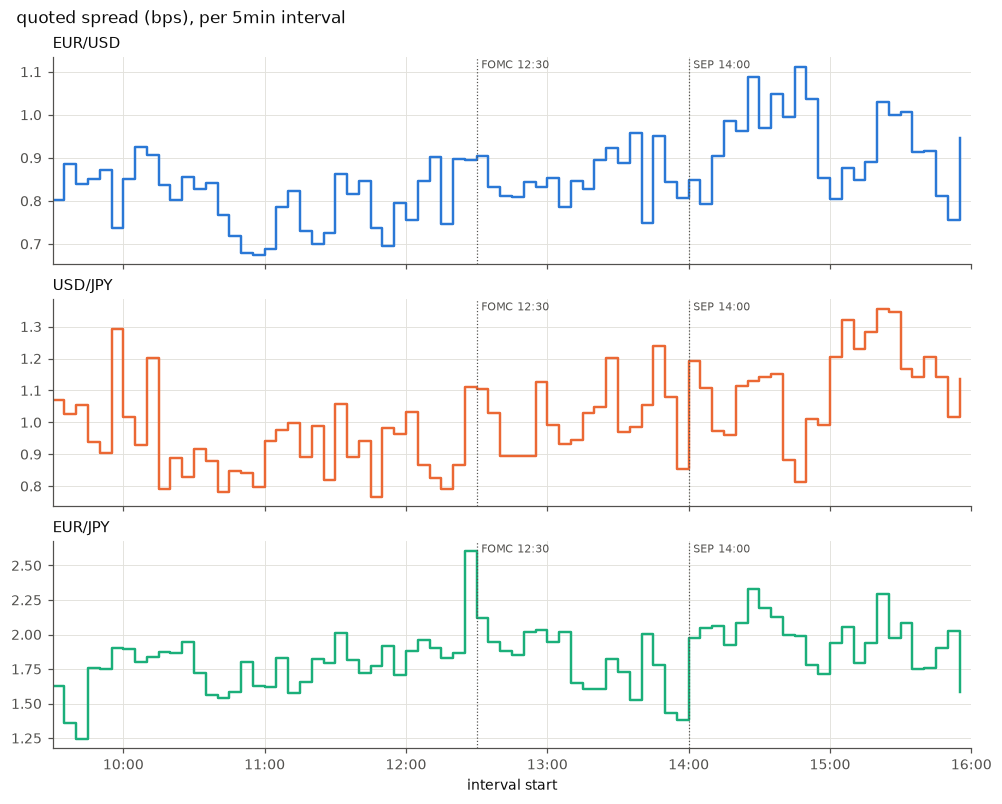

In [23]:
plots.plot_liquidity(books, "spread_bps", marks=_fomc, save="fx_spread_bps_5min");

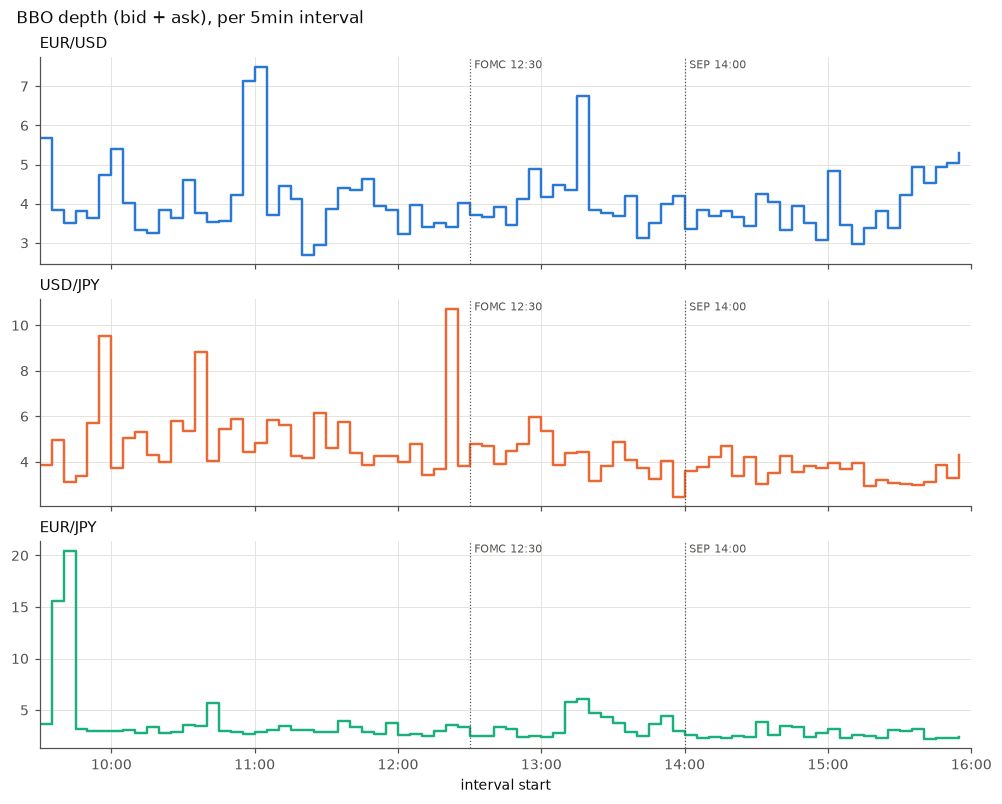

In [24]:
plots.plot_liquidity(books, "depth", marks=_fomc, save="fx_depth_5min");

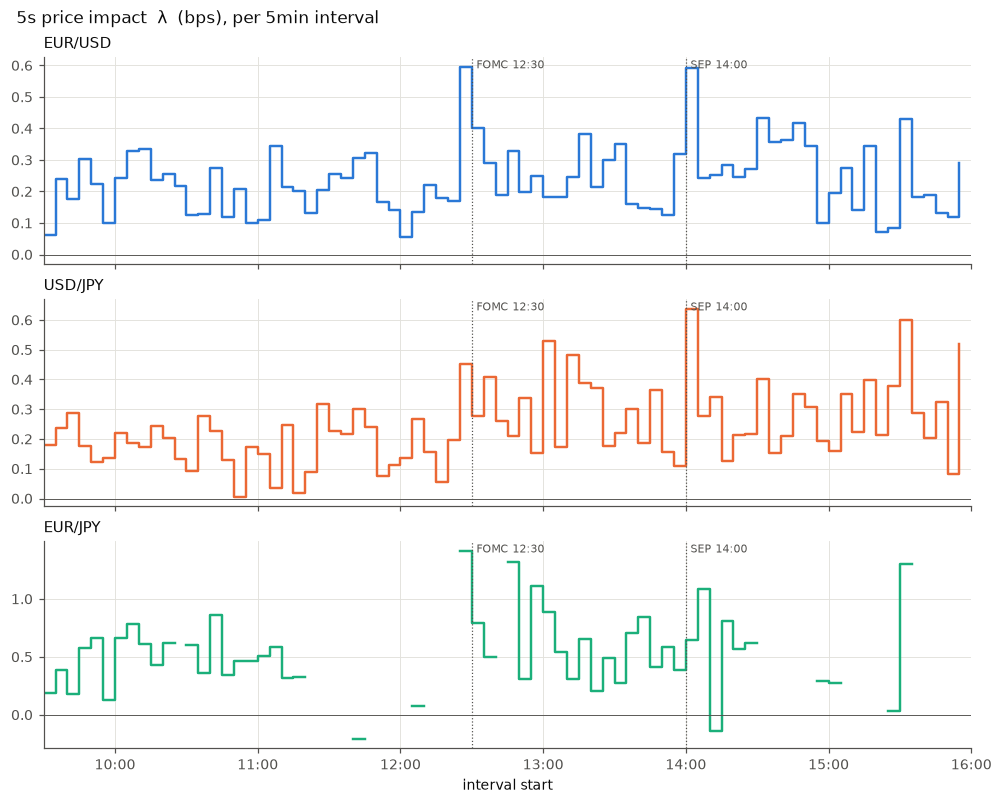

In [25]:
plots.plot_liquidity(books, "lambda_bps", marks=_fomc, save="fx_lambda_bps_5min");

### One-minute transaction returns by half hour

Thirty one-minute returns per interval, so the lag-1 autocorrelation is estimated
on 29 pairs and the dashed lines at ±1.96/√n show how little a single half hour can
say on its own; the shape across the day is the thing to read.

In [26]:
ret30 = {p: plots.returns_by_interval(b) for p, b in books.items()}
pd.concat(ret30, axis=1, names=["pair", ""]).round(3)

pair                      EUR/USD                  USD/JPY             \
                    variance_bps2    ac1   n variance_bps2    ac1   n   
2012-01-25 09:30:00         3.807 -0.045  29         2.981  0.314  29   
2012-01-25 10:00:00         3.269 -0.441  30         1.310 -0.437  30   
2012-01-25 10:30:00         1.781 -0.115  30         3.579 -0.230  30   
2012-01-25 11:00:00         1.601  0.065  30         1.521  0.132  30   
2012-01-25 11:30:00         2.042  0.140  30         1.450 -0.175  30   
2012-01-25 12:00:00         7.815  0.573  30        17.180  0.009  30   
2012-01-25 12:30:00        14.972  0.094  30        22.347 -0.116  30   
2012-01-25 13:00:00        22.008 -0.150  30        11.482 -0.186  30   
2012-01-25 13:30:00         4.653 -0.285  30         6.195 -0.028  30   
2012-01-25 14:00:00        17.267  0.052  30        16.377  0.060  30   
2012-01-25 14:30:00         5.733  0.295  30         4.222  0.248  30   
2012-01-25 15:00:00         5.593 -0.212  30         4.360  0.087  30   
2012-01-25 15:30:00         5.801 -0.186  30         4.710 -0.025  30   

pair                      EUR/JPY             
                    variance_bps2    ac1   n  
2012-01-25 09:30:00         3.926  0.093  29  
2012-01-25 10:00:00         2.683 -0.354  30  
2012-01-25 10:30:00         3.542 -0.037  30  
2012-01-25 11:00:00         3.719  0.005  30  
2012-01-25 11:30:00         3.397 -0.178  30  
2012-01-25 12:00:00         8.416 -0.371  30  
2012-01-25 12:30:00        17.769 -0.256  30  
2012-01-25 13:00:00         5.928  0.123  30  
2012-01-25 13:30:00         5.753 -0.030  30  
2012-01-25 14:00:00        11.799 -0.119  30  
2012-01-25 14:30:00         6.033 -0.362  30  
2012-01-25 15:00:00         3.325  0.268  30  
2012-01-25 15:30:00         4.522 -0.431  30

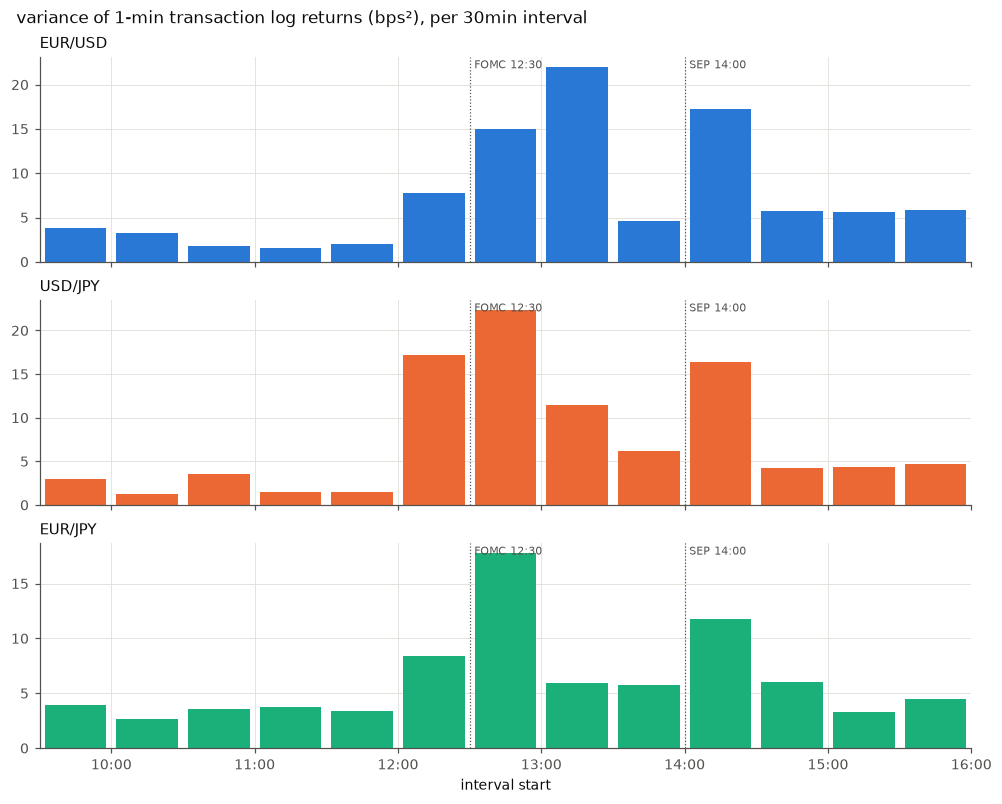

In [27]:
plots.plot_returns(books, "variance_bps2", marks=_fomc, save="fx_variance_bps2_30min");

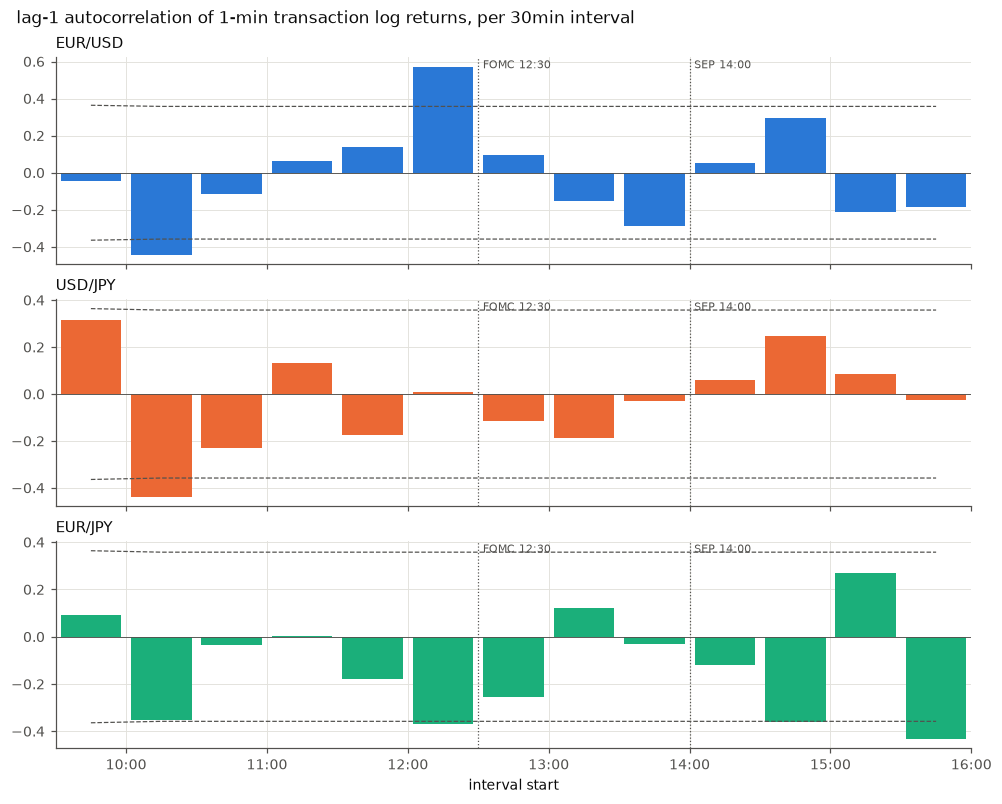

In [28]:
plots.plot_returns(books, "ac1", marks=_fomc, save="fx_ac1_30min");

### Autocorrelation functions

One row per pair, midquote on the left and transaction price on the right; the
shaded band is ±1.96/√n. Ten lags is enough for every series to have settled.

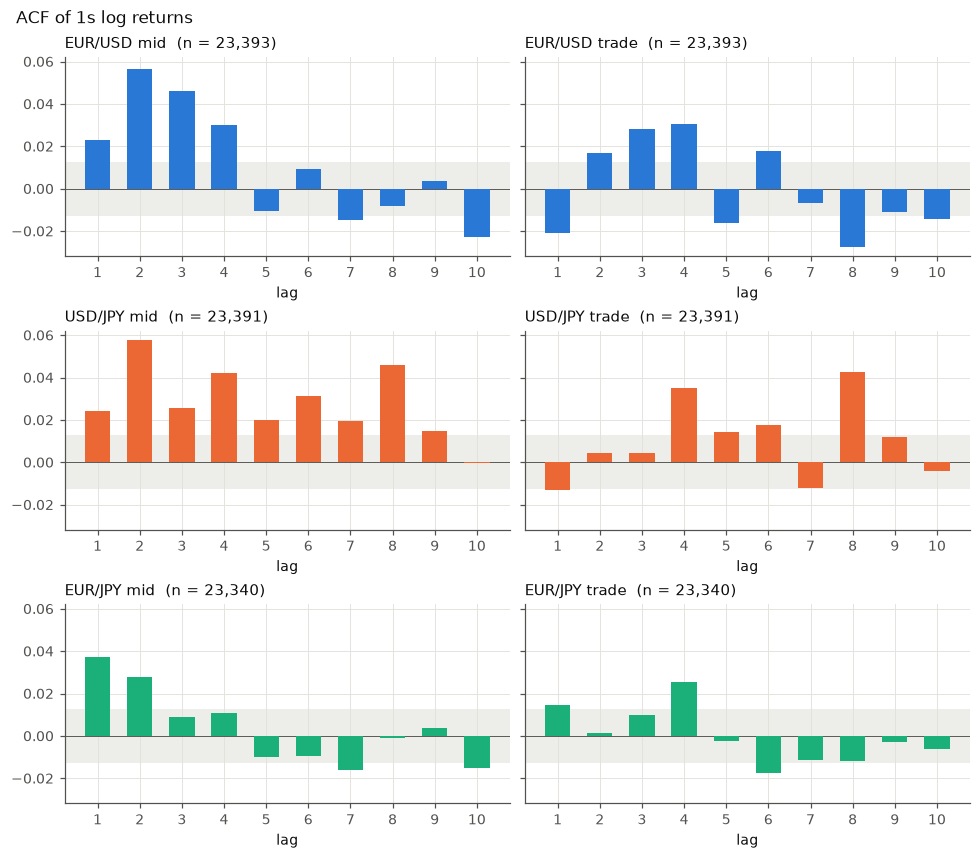

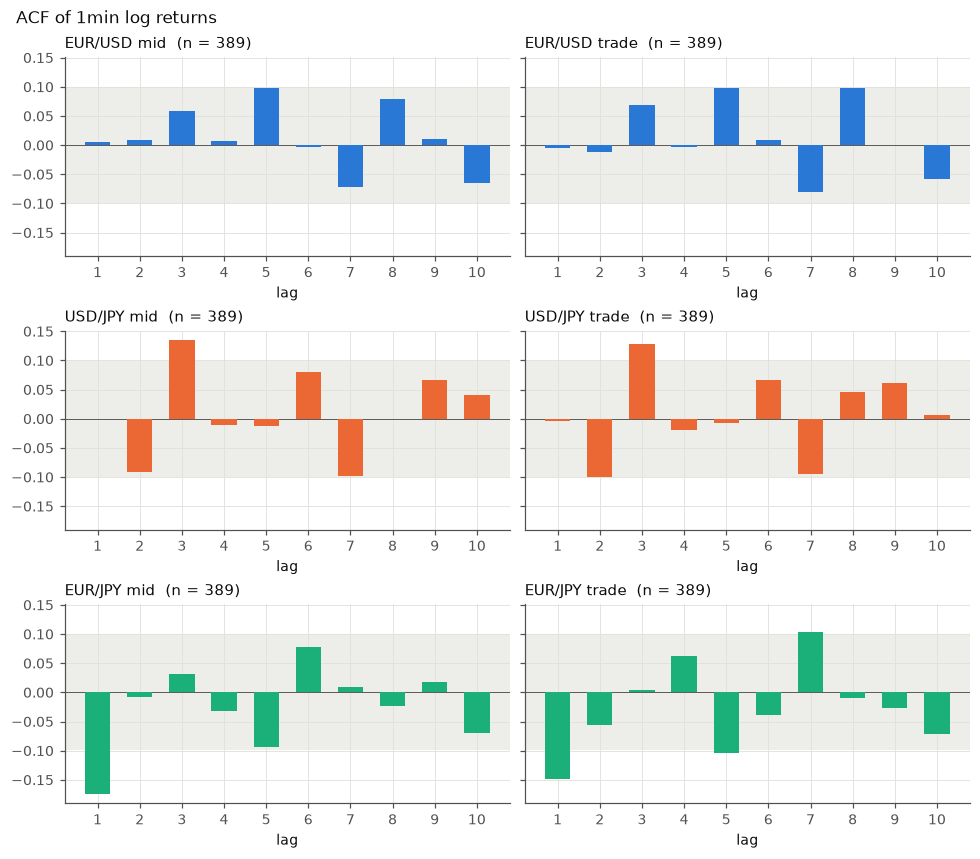

In [29]:
for _fq in FREQS:
    plots.plot_acf({f"{p} {s_}": i[p][_fq][s_] for p in books for s_ in ("mid", "trade")},
                   lags=10, save=f"fx_acf_{_fq}", title=f"ACF of {_fq} log returns")

## Summary statistics table

The homework asks for one table: every part at the daily level, one column per
pair. Parts (a)–(g) are the mean of their per-minute values, so each row is the
average minute; (h)–(k) are whole-session figures at both sampling frequencies.
`hfstats.headline` builds the same column for the equities, so the two panels stack
into one table. Levels are comparable within this panel; against the equities only
the relative rows — spreads in basis points, realized variance, autocorrelations —
mean the same thing, because sizes here are millions of base currency, not shares.

In [30]:
table = pd.DataFrame({p: hs.headline(b) for p, b in books.items()})
table.to_csv(plots.FIG_DIR / "summary_currencies.csv")
table.round(4)

,EUR/USD,USD/JPY,EUR/JPY
(a) dollar volume / min,79.3591,24.8026,7.2682
(b) trades / min,37.2692,15.4897,3.9538
(b) orders or book messages / min,918.4897,459.6974,460.1103
(c) open,1.2974,78.0530,101.2430
(c) high,1.3121,78.2880,101.9490
(c) low,1.2947,77.5600,101.2000
(c) close,1.3113,77.7300,101.9200
"(d) VWAP, session",1.3032,77.9276,101.5209
(e) spread,0.0001,0.0079,0.0187
(e) spread (bps),0.8548,1.0130,1.8415


## Observations

**1. The liquidity ordering is exactly the one the triangle implies.** EUR/USD quotes
at 0.86 bps, USD/JPY at 1.01, EUR/JPY at 1.84 — the cross costs roughly as much as
its two legs added together, which is what it should cost if the only way to make a
price in it is to lay it off through the dollar. The same ordering runs through every
other measure: EUR/JPY has the thinnest touch (3.5 mm against 4.1 and 4.4), the
shallowest ten-level book (37 mm against ~50), the largest price impact (0.53 bps
against 0.22), and the fewest trades (1,542 against 14,535).

**2. The cross is quoted far more than it is traded.** EUR/JPY carries 116 book
messages per print, against 25 for EUR/USD and 30 for USD/JPY, despite being much the
quietest pair. A market maker in the cross has to re-quote whenever *either* leg
moves, so its message traffic is driven by the majors' volatility rather than by its
own trading — an order-flow cost with no corresponding revenue, and part of why the
cross is quoted wider.

**3. Bounce and staleness pull the variance in opposite directions.** At a fixed
frequency, transaction RV exceeds midquote RV (EUR/USD at 1s: 2927 vs 2320 bps²) and
transaction returns are negatively autocorrelated at lag 1 while midquote returns are
not — textbook bid–ask bounce. But across frequencies the midquote signature *rises*
rather than falls, because at one second 43–64% of midquote returns are exactly zero:
with a one-pip spread and a tenth-pip tick, the EBS mid usually has not moved. The
high-frequency RV is therefore biased *down* by discreteness, not up by noise, which
is the opposite of the equity case and worth keeping in mind before quoting any
one-second variance as an estimate of true volatility.

**4. EUR/JPY's one-minute returns are strongly mean-reverting, and it is not simply
non-trading.** Its one-minute autocorrelation is −0.17 for the midquote and −0.15 for
transactions, against essentially zero for both majors (t = −3.4 on 390
observations). Forward-filling is the obvious suspect, since the cross prints in only
79% of minutes against 97–100% for the majors — but that cannot explain the
*midquote* figure, because EUR/JPY updates its quote 1.5 times a second and only 2.3%
of its one-minute mid returns are zero. What fits instead is a transitory component in
the cross's quoted mid: with a spread twice as wide and a book a quarter thinner,
where the cross's mid sits inside its spread is itself noisy, and that noise reverses.
The realized variance corroborates it — EUR/JPY's midquote RV *falls* from 2317 bps²
at one minute to 1655 at five, as the transitory part averages out, while both majors
rise over the same range. The practical reading is that the cross's mid is a
materially noisier estimate of its efficient price than either major's, which is the
same fact as its wider spread seen from the return side.

**5. Triangular arbitrage exists, and is about as small as theory says it should be.**
Gross deviations appear in 0.39% of seconds across 63 episodes, with a median
duration of one second (max seven), a mean edge of 0.29 bps and a median round-trip
size of 0.77 mm EUR — about $3,100 for the whole session, before any cost, assuming
all three legs fill in full at the quoted price. Charging a few EUR/JPY ticks per
round trip roughly halves it. The edge is real rather than a sampling artefact: the
quotes behind an opportunity are *fresher* than average (median stalest leg 1.4 s
against 2.1 s), which is the opposite of the staleness signature. For scale: across
all live seconds the median deviation is −1.58 bps, i.e. the triangle normally sits
inside itself by about the width of the cross's own 1.84 bps spread, and even when it
does open the mean edge is 0.29 bps — a sixth of that spread — with the largest of the
day, 1.78 bps, still short of one full spread. The no-arbitrage relation therefore
holds to within the cost of crossing the cross, and the residual is a latency race
rather than a return available to a price-taker.

**6. Both the deviations and the volatility cluster in the same window, and the
window is the FOMC.** The opportunities are concentrated in the first half hour
(22 of the 91 open seconds) and after 13:00 (53 of 91), which is also where the
day's largest moves sit — EUR/USD rallies 1.1% over the session, most of it between
12:25 and 14:30. The file carries no timezone, but the clock identifies itself: on
2012-01-25 the Committee released its first-ever rate projections at 14:00 ET, and
EUR/USD drops 20 bps in the 14:00–14:01 minute exactly; the statement itself was
scheduled for 12:30 ET, and the tape goes from zero prints in the 12:26 minute to
231 in 12:28 as the mid jumps 17 bps — so the timestamps are Eastern, and the day's
volatility is the Fed's. The spread plot shows the same thing from the liquidity
side: EUR/JPY's five-minute spread spikes to 2.6 bps in the 12:25 interval, its
widest of the day, and impact λ in all three pairs peaks in the 12:30 and 14:00
intervals. The mechanism is the standard one: the triangle breaks when prices move
fast enough that the three books adjust at different speeds, so arbitrage frequency
is a symptom of information arriving, not of a market that is generally mispriced.

**7. The intraday pattern is announcement-shaped rather than U-shaped.** On the
two majors the spread is narrowest late in the morning (0.68 bps for EUR/USD at
10:55, 0.77 for USD/JPY at 11:45) and widens through the afternoon, ending 30–40%
wider than its morning low; the cross is different again, tightest in the first
ten minutes and widest — 2.6 bps, twice its mean — in the 12:25 interval that
contains the pre-statement jump. Depth shows no open-of-day trough at all: the
thinnest five-minute touch on each pair falls mid-session (11:20, 13:55, 15:40),
and EUR/JPY's touch is *deepest* at the open. Impact λ peaks on all three pairs in
the 12:25 and 14:00 intervals, and the half-hourly variance of one-minute returns
is five to ten times its mid-morning level in the 12:30–13:30 and 14:00–14:30
windows. FX has no opening auction and no overnight close on a 24-hour market, so
the equity U-shape has no reason to appear; what shapes this day is the scheduled
release, and the liquidity measures respond to it the way the models say — spreads
and impact up, as the adverse-selection component rises when information arrives.
The lag-1 autocorrelation of one-minute transaction returns is negative in most half
hours, the bounce signature, but flips to +0.57 for EUR/USD in the 12:00–12:30
window, where the price trends into the release: at one-minute sampling a fast
one-directional move reads as momentum, and the sign of the autocorrelation says
which of the two effects, bounce or drift, is winning in that half hour.